# Gordon networks & Desikan-Killiany atlas surface plots

Plots the **Gordon (2016) network atlas** and the **Desikan-Killiany (DK) cortical atlas** on the fs_LR 32k inflated surface.

**How to use**
1. Edit the selections in **Section 1** (`"all"` or a list of networks / regions).
2. Run all cells. Figures go to `derivatives/figures/` (PNG only).

Notes
- Gordon: projected from `gordon_networks_222.nii` (MNI152) to fs_LR 32k with `neuromaps`, same method as `1c-plsc-figures.ipynb`.
- DK: the Lausanne / Cammoun et al. (2012) scale-33 parcellation (the DK cortical regions) in fs_LR 32k, fetched with `netneurotools`. It downloads once (~a few MB) to `~/nnt-data`.

In [46]:
import difflib
from os.path import join, exists
from os import makedirs

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, to_rgba
from matplotlib.patches import Patch

from neuromaps import transforms
from neuromaps.datasets import fetch_fslr
from netneurotools.datasets import fetch_cammoun2012
from gradec.utils import _zero_medial_wall
from surfplot import Plot

%matplotlib inline

In [47]:
# directories (absolute, so it works no matter where the kernel starts)
from pathlib import Path

PROJECT = Path.home() / "Desktop" / "struc-func-plsc"
fig_dir = PROJECT / "derivatives" / "figures"     # PNGs only
gordon_path = PROJECT / "gordon_networks_222.nii"

fig_dir.mkdir(parents=True, exist_ok=True)
assert gordon_path.exists(), f"Gordon atlas not found: {gordon_path}"

## 1. Pick what to plot

Edit this cell, then run everything below it.
- **Gordon**: `"all"`, or a list of IDs or names, e.g. `[1, 10, 13, 4]` or `["Default", "CON", "Visual"]` (full names, short names, and abbreviations all work).
- **DK**: `"all"`, or a list of region names, e.g. `["superiorfrontal", "precuneus", "insula"]`. Run the *list available regions* cell in Section 2 to see the exact names; close misspellings get a suggestion.
- **DK colors**: `DK_COLORS` takes hex codes per region (`{"precuneus": "#F89400"}`) or one hex code for all selected regions (`"#8D0102"`). Regions you leave out use the atlas colors.
- **DK lobes**: `PLOT_DK_LOBES = True` also saves `DK_lobes.png`, with all 34 regions colored by lobe (frontal, cingulate, parietal, temporal, occipital, insula). Set the lobe colors in `LOBE_COLORS`. `LOBE_REGION_OUTLINES` draws each region's border (color in `LOBE_OUTLINE_COLOR`, white by default) on top with no fill. It follows `DK_HEMI` and `RUN_TAG` but not `DK_SELECTION`.

In [48]:
# ---- EDIT HERE -------------------------------------------------------------
GORDON_SELECTION = "all"          # e.g. [1, 10, 13, 4]  (dim 1)  or  [1, 3, 11, 4]  (dim 3)

DK_SELECTION = "all"              # e.g. ["superiorfrontal", "precuneus", "insula"]
DK_HEMI = "both"                  # "both", "lh", or "rh"
DK_COLORS = {                    # hex code per region (random placeholders for now; edit freely)
    # frontal
    "superiorfrontal": "#390062",
    "rostralmiddlefrontal": "#0CCE35",
    "caudalmiddlefrontal": "#8CD0A4",
    "parsopercularis": "#7D6277",
    "parstriangularis": "#7248AD",
    "parsorbitalis": "#477183",
    "lateralorbitofrontal": "#347A3F",
    "medialorbitofrontal": "#2C833F",
    "frontalpole": "#D80623",
    "precentral": "#1045D1",
    "paracentral": "#0F4194",
    # cingulate
    "rostralanteriorcingulate": "#2FF8D2",
    "caudalanteriorcingulate": "#6FF151",
    "posteriorcingulate": "#771F54",
    "isthmuscingulate": "#0D961F",
    # parietal
    "postcentral": "#65CE0C",
    "supramarginal": "#D6CB4D",
    "superiorparietal": "#70DD97",
    "inferiorparietal": "#E5FEBA",
    "precuneus": "#8E6F03",
    # temporal
    "superiortemporal": "#0353CE",
    "middletemporal": "#51BEDD",
    "inferiortemporal": "#D860EA",
    "bankssts": "#AE3550",
    "transversetemporal": "#8E4527",
    "temporalpole": "#4F9B02",
    "fusiform": "#6E3D9A",
    "parahippocampal": "#AC561E",
    "entorhinal": "#3454E7",
    # occipital
    "lateraloccipital": "#2F7C62",
    "lingual": "#C285D4",
    "cuneus": "#3184CF",
    "pericalcarine": "#B7CC25",
    # insula
    "insula": "#B01AF6",
}                                 # or one hex string for every region, e.g. "#8D0102"; regions left out keep the atlas color

PLOT_DK_LOBES = True              # extra DK figure: every region colored by its lobe (always all 34 regions)
LOBE_COLORS = {                   # hex code per lobe
    "frontal":   "#E15759",
    "cingulate": "#F28E2B",
    "parietal":  "#4E79A7",
    "temporal":  "#59A14F",
    "occipital": "#B07AA1",
    "insula":    "#EDC948",
}
LOBE_REGION_OUTLINES = True       # draw each DK region's border on top of the lobe colors (no fill)
LOBE_OUTLINE_COLOR = "#FFFFFF"    # outline color

PLOT_COMBINED = True              # one brain with every selected network / region
PLOT_INDIVIDUAL = False           # one brain per selected network / region
SHOW_LEGEND = True
LEGEND_MAX_ITEMS = 20             # legend is skipped if there are more items than this
SHOW_TITLE = False

RUN_TAG = ""                      # added to filenames so selections don't overwrite each other, e.g. "dim1"
# ----------------------------------------------------------------------------

## 2. Atlas definitions

In [49]:
# ---- Gordon networks ----
gordon_hex = {
    6: "#5B040D",   # Auditory
    10: "#8D0102",  # Cingulo-opercular
    8: "#CE4E05",   # Cingulo-parietal
    1: "#F89400",   # Default
    13: "#DCAA32",  # Dorsal Attention
    5: "#018900",   # Fronto-parietal
    9: "#004502",   # Retrosplenial Temporal
    2: "#1BBFE0",   # Sensorimotor Hand
    3: "#0050BF",   # Sensorimotor Mouth
    12: "#010F89",  # Salience
    11: "#8A388F",  # Ventral Attention
    4: "#44256B",   # Visual
}
gordon_full_names = {
    6: "Auditory Network", 10: "Cingulo-Opercular Network", 8: "Cingulo-Parietal Network",
    1: "Default Network", 13: "Dorsal Attention Network", 5: "Fronto-Parietal Network",
    9: "Retrosplenial Temporal Network", 2: "Sensorimotor Hand Network",
    3: "Sensorimotor Mouth Network", 12: "Salience Network",
    11: "Ventral Attention Network", 4: "Visual Network",
}
gordon_file_names = {
    6: "Auditory", 10: "CinguloOpercular", 8: "CinguloParietal", 1: "Default",
    13: "DorsalAttention", 5: "FrontoParietal", 9: "RetrosplenialTemporal",
    2: "SensorimotorHand", 3: "Sensorimotor", 12: "Salience",
    11: "VentralAttention", 4: "Visual",
}
gordon_abbrev = {
    6: "AN", 10: "CON", 8: "CPN", 1: "DN", 13: "DAN", 5: "FPN",
    9: "RTN", 2: "SHN", 3: "SMN", 12: "SN", 11: "VAN", 4: "VN",
}
GORDON_ORDER = [6, 10, 8, 1, 13, 5, 9, 2, 3, 12, 11, 4]


def _key(s):
    return "".join(ch for ch in str(s).lower() if ch.isalnum())


# every accepted spelling -> network ID
_gordon_lookup = {}
for net in GORDON_ORDER:
    full = gordon_full_names[net]
    for alias in (net, full, full.replace(" Network", ""), gordon_file_names[net], gordon_abbrev[net]):
        _gordon_lookup[_key(alias)] = net
_gordon_lookup[_key("Default Mode")] = 1
_gordon_lookup[_key("DMN")] = 1


def resolve_gordon(selection):
    # Turn "all" or a list of IDs/names into a list of Gordon network IDs.
    if isinstance(selection, str) and selection.lower() == "all":
        return list(GORDON_ORDER)
    if isinstance(selection, (str, int)):
        selection = [selection]
    nets = []
    for item in selection:
        k = _key(item)
        if k not in _gordon_lookup:
            close = difflib.get_close_matches(k, _gordon_lookup.keys(), n=3)
            raise ValueError(f"Unknown Gordon network {item!r}. Close matches: {close}. "
                             f"Valid IDs: {GORDON_ORDER}")
        net = _gordon_lookup[k]
        if net not in nets:
            nets.append(net)
    return nets


print("Gordon networks:")
for net in GORDON_ORDER:
    print(f"  {net:>2}  {gordon_abbrev[net]:<4} {gordon_full_names[net]}")

Gordon networks:
   6  AN   Auditory Network
  10  CON  Cingulo-Opercular Network
   8  CPN  Cingulo-Parietal Network
   1  DN   Default Network
  13  DAN  Dorsal Attention Network
   5  FPN  Fronto-Parietal Network
   9  RTN  Retrosplenial Temporal Network
   2  SHN  Sensorimotor Hand Network
   3  SMN  Sensorimotor Mouth Network
  12  SN   Salience Network
  11  VAN  Ventral Attention Network
   4  VN   Visual Network


In [42]:
# ---- Desikan-Killiany (Cammoun 2012 scale-33, fs_LR 32k) ----
_DK_DROP = {"unknown", "medialwall", "corpuscallosum", "???", ""}
_HEMI_PREFIXES = ("ctx-lh-", "ctx-rh-", "ctx_lh_", "ctx_rh_", "lh.", "rh.", "lh_", "rh_",
                  "lh-", "rh-", "l_", "r_", "left-", "right-")


def _clean_dk_name(name):
    n = str(name).strip().lower()
    for p in _HEMI_PREFIXES:
        if n.startswith(p):
            n = n[len(p):]
            break
    return n.replace("_", "").replace("-", "").replace(" ", "")


def load_dk_hemi(path):
    # Return {'data': per-vertex int labels, 'regions': {name: (key, rgba)}} for one hemisphere.
    gii = nib.load(path)
    data = np.asarray(gii.darrays[0].data).astype(int)
    regions = {}
    for lab in gii.labeltable.labels:
        name = _clean_dk_name(lab.label)
        if lab.key == 0 or name in _DK_DROP:
            continue
        rgba = tuple(0.0 if v is None else float(v) for v in lab.rgba)
        regions[name] = (lab.key, rgba)
    return {"data": data, "regions": regions}


dk_files = fetch_cammoun2012(version="fslr32k")["scale033"]
dk_lh_path = [f for f in dk_files if "hemi-L" in f][0]
dk_rh_path = [f for f in dk_files if "hemi-R" in f][0]
dk = {"lh": load_dk_hemi(dk_lh_path), "rh": load_dk_hemi(dk_rh_path)}

DK_REGIONS = sorted(set(dk["lh"]["regions"]) | set(dk["rh"]["regions"]))


def resolve_dk(selection):
    # Turn "all" or a list of region names into a list of cleaned DK region names.
    if isinstance(selection, str) and selection.lower() == "all":
        return list(DK_REGIONS)
    if isinstance(selection, str):
        selection = [selection]
    names = []
    for item in selection:
        n = _clean_dk_name(item)
        if n not in DK_REGIONS:
            close = difflib.get_close_matches(n, DK_REGIONS, n=3)
            raise ValueError(f"Unknown DK region {item!r}. Close matches: {close}")
        if n not in names:
            names.append(n)
    return names


def dk_region_color(name, i, n_total):
    # Use the atlas's own label color; fall back to a qualitative palette if it's missing/black.
    for hemi in ("lh", "rh"):
        if name in dk[hemi]["regions"]:
            rgba = dk[hemi]["regions"][name][1]
            if sum(rgba[:3]) > 0.05:
                return tuple(rgba[:3]) + (1.0,)
    cmap = plt.get_cmap("tab20" if n_total <= 20 else "hsv")
    return cmap(i % 20) if n_total <= 20 else cmap(i / max(n_total, 1))

In [43]:
# list available DK regions (use these names in DK_SELECTION)
print(f"{len(DK_REGIONS)} DK regions per hemisphere:")
for i in range(0, len(DK_REGIONS), 4):
    print("  " + "".join(f"{r:<28}" for r in DK_REGIONS[i:i + 4]))

34 DK regions per hemisphere:
  bankssts                    caudalanteriorcingulate     caudalmiddlefrontal         cuneus                      
  entorhinal                  frontalpole                 fusiform                    inferiorparietal            
  inferiortemporal            insula                      isthmuscingulate            lateraloccipital            
  lateralorbitofrontal        lingual                     medialorbitofrontal         middletemporal              
  paracentral                 parahippocampal             parsopercularis             parsorbitalis               
  parstriangularis            pericalcarine               postcentral                 posteriorcingulate          
  precentral                  precuneus                   rostralanteriorcingulate    rostralmiddlefrontal        
  superiorfrontal             superiorparietal            superiortemporal            supramarginal               
  temporalpole                transversetemporal  

In [50]:
# ---- shared surface + plotting helpers ----
surfaces = fetch_fslr(density="32k")
lh_surf, rh_surf = surfaces["inflated"]
sulc_lh, sulc_rh = surfaces["sulc"]


def solid_cmap(color, name="solid"):
    return LinearSegmentedColormap.from_list(name, [color, color], N=256)


def finish_and_save(fig, legend_items, title, filename):
    # Add optional legend/title, save to fig_dir, and show.
    if SHOW_LEGEND and legend_items and len(legend_items) <= LEGEND_MAX_ITEMS:
        handles = [Patch(facecolor=c, edgecolor="black") for _, c in legend_items]
        labels = [lab for lab, _ in legend_items]
        fig.legend(handles=handles, labels=labels, loc="lower center",
                   ncol=min(len(handles), 4), frameon=False, bbox_to_anchor=(0.5, -0.05))
    if SHOW_TITLE and title:
        fig.suptitle(title, y=0.95, fontsize=14, fontweight="bold")
    out = join(fig_dir, filename)
    fig.savefig(out, dpi=300, bbox_inches="tight", facecolor="white", edgecolor="none")
    print(f"✓ Saved {out}")
    plt.show()


def name_tag(parts, all_selected, label):
    # Build a short filename tag for a selection.
    if all_selected:
        tag = "all"
    elif len(parts) <= 4:
        tag = "_".join(parts)
    else:
        tag = f"{len(parts)}{label}"
    return tag + (f"_{RUN_TAG}" if RUN_TAG else "")

## 3. Gordon networks

sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348


Plotting Gordon networks: ['AN', 'CON', 'CPN', 'DN', 'DAN', 'FPN', 'RTN', 'SHN', 'SMN', 'SN', 'VAN', 'VN']


sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348
sizeof_hdr should be 348; set sizeof_hdr to 348


✓ Saved /Users/chloehampson/Desktop/struc-func-plsc/derivatives/figures/Gordon_all.png


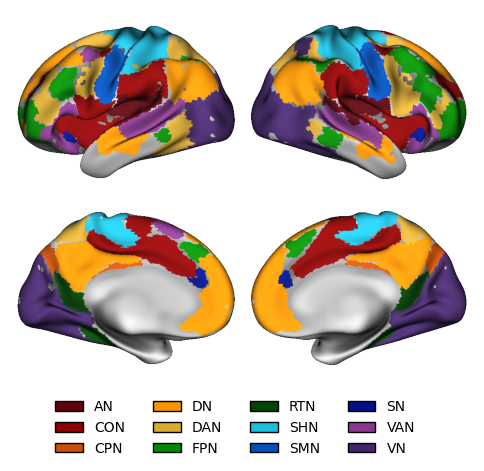

In [51]:
gordon_nets = resolve_gordon(GORDON_SELECTION)
print("Plotting Gordon networks:", [gordon_abbrev[n] for n in gordon_nets])

gordon_img = nib.load(gordon_path)
gordon_data = gordon_img.get_fdata()

# project each selected network's binary mask to fs_LR 32k once, then reuse
gordon_surf = {}
for net in gordon_nets:
    mask_img = nib.Nifti1Image((gordon_data == net).astype(np.float32), gordon_img.affine, gordon_img.header)
    lh_net, rh_net = transforms.mni152_to_fslr(mask_img, fslr_density="32k")
    gordon_surf[net] = _zero_medial_wall(lh_net, rh_net, space="fsLR", density="32k")


def plot_gordon(nets, filename, title=None):
    p = Plot(surf_lh=lh_surf, surf_rh=rh_surf, layout="grid")
    p.add_layer({"left": sulc_lh, "right": sulc_rh}, cmap="binary_r", cbar=False)
    for net in nets:
        lh_net, rh_net = gordon_surf[net]
        p.add_layer({"left": lh_net, "right": rh_net},
                    cmap=solid_cmap(gordon_hex[net], f"net_{net}"),
                    cbar=False, color_range=(0, 1))
    fig = p.build()
    legend = [(gordon_abbrev[n], gordon_hex[n]) for n in nets]
    finish_and_save(fig, legend, title, filename)


all_gordon = set(gordon_nets) == set(GORDON_ORDER)

if PLOT_COMBINED:
    tag = name_tag([gordon_file_names[n] for n in gordon_nets], all_gordon, "networks")
    plot_gordon(gordon_nets, f"Gordon_{tag}.png",
                title=" + ".join(gordon_abbrev[n] for n in gordon_nets))

if PLOT_INDIVIDUAL:
    for net in gordon_nets:
        suffix = f"_{RUN_TAG}" if RUN_TAG else ""
        plot_gordon([net], f"Gordon_{gordon_file_names[net]}{suffix}.png",
                    title=gordon_full_names[net])

## 4. Desikan-Killiany atlas

Plotting 34 DK region(s) on lh, rh
✓ Saved /Users/chloehampson/Desktop/struc-func-plsc/derivatives/figures/DK_all.png


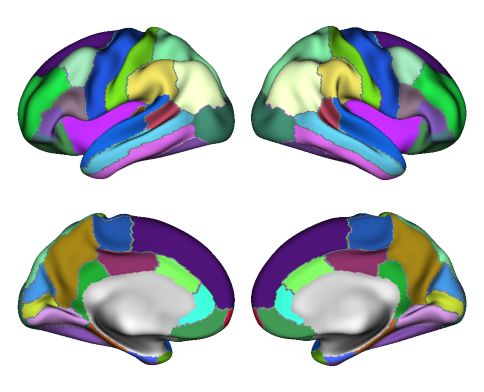

In [52]:
dk_names = resolve_dk(DK_SELECTION)
hemis = ["lh", "rh"] if DK_HEMI == "both" else [DK_HEMI]
assert all(h in ("lh", "rh") for h in hemis), 'DK_HEMI must be "both", "lh", or "rh"'
print(f"Plotting {len(dk_names)} DK region(s) on {', '.join(hemis)}")

dk_colors = {n: dk_region_color(n, i, len(dk_names)) for i, n in enumerate(dk_names)}

# apply the hex codes from DK_COLORS (Section 1)
if isinstance(DK_COLORS, str):
    _custom = {n: DK_COLORS for n in dk_names}
else:
    _custom = {}
    for region, hex_code in DK_COLORS.items():
        n = _clean_dk_name(region)
        if n not in DK_REGIONS:
            close = difflib.get_close_matches(n, DK_REGIONS, n=3)
            print(f"Warning: DK_COLORS has unknown region {region!r} (skipped). Close matches: {close}")
            continue
        _custom[n] = hex_code
for n, hex_code in _custom.items():
    try:
        rgba = to_rgba(hex_code)
    except ValueError:
        raise ValueError(f"DK_COLORS: {hex_code!r} for {n!r} is not a valid color (use e.g. '#F89400')")
    if n in dk_colors:
        dk_colors[n] = rgba
    else:
        print(f"Note: {n!r} has a color in DK_COLORS but isn't in DK_SELECTION, so it isn't plotted.")


def dk_surface_arrays(names):
    # Code the selected regions as 1..K on each hemisphere (0 = not shown / transparent).
    arrays = {}
    for hemi in ("lh", "rh"):
        arr = np.zeros(dk[hemi]["data"].shape, dtype=float)
        if hemi in hemis:
            for k, name in enumerate(names, start=1):
                if name in dk[hemi]["regions"]:
                    key = dk[hemi]["regions"][name][0]
                    arr[dk[hemi]["data"] == key] = k
        arrays[hemi] = arr
    return arrays["lh"], arrays["rh"]


def plot_dk(names, filename, title=None):
    lh_arr, rh_arr = dk_surface_arrays(names)
    cmap = ListedColormap([dk_colors[n] for n in names])
    p = Plot(surf_lh=lh_surf, surf_rh=rh_surf, layout="grid")
    p.add_layer({"left": sulc_lh, "right": sulc_rh}, cmap="binary_r", cbar=False)
    p.add_layer({"left": lh_arr, "right": rh_arr}, cmap=cmap, cbar=False,
                color_range=(0.5, len(names) + 0.5))
    fig = p.build()
    legend = [(n, dk_colors[n]) for n in names]
    finish_and_save(fig, legend, title, filename)


hemi_tag = "" if DK_HEMI == "both" else f"_{DK_HEMI}"
all_dk = set(dk_names) == set(DK_REGIONS)

if PLOT_COMBINED:
    tag = name_tag(dk_names, all_dk, "regions")
    plot_dk(dk_names, f"DK_{tag}{hemi_tag}.png", title="Desikan-Killiany")

if PLOT_INDIVIDUAL:
    for name in dk_names:
        suffix = f"_{RUN_TAG}" if RUN_TAG else ""
        plot_dk([name], f"DK_{name}{suffix}{hemi_tag}.png", title=name)

## 5. Desikan-Killiany regions by lobe

Every DK region colored by its lobe. The lobe assignments are in `DK_LOBES` below (same grouping as the `DK_COLORS` comments in Section 1).

✓ Saved /Users/chloehampson/Desktop/struc-func-plsc/derivatives/figures/DK_lobes.png


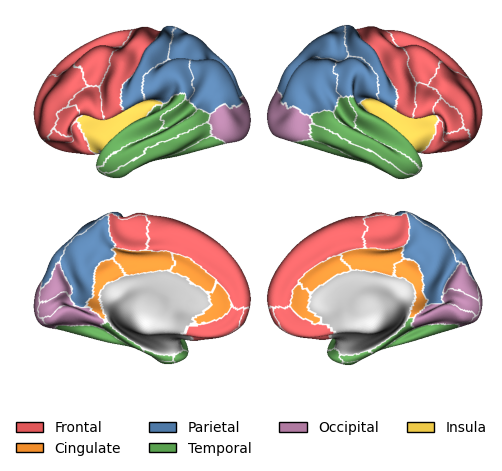

In [53]:
DK_LOBES = {
    "frontal": ["superiorfrontal", "rostralmiddlefrontal", "caudalmiddlefrontal", "parsopercularis",
                "parstriangularis", "parsorbitalis", "lateralorbitofrontal", "medialorbitofrontal",
                "frontalpole", "precentral", "paracentral"],
    "cingulate": ["rostralanteriorcingulate", "caudalanteriorcingulate", "posteriorcingulate",
                  "isthmuscingulate"],
    "parietal": ["postcentral", "supramarginal", "superiorparietal", "inferiorparietal", "precuneus"],
    "temporal": ["superiortemporal", "middletemporal", "inferiortemporal", "bankssts",
                 "transversetemporal", "temporalpole", "fusiform", "parahippocampal", "entorhinal"],
    "occipital": ["lateraloccipital", "lingual", "cuneus", "pericalcarine"],
    "insula": ["insula"],
}
LOBE_ORDER = list(DK_LOBES)

# check the lobe lists against the atlas and the colors
region_to_lobe = {r: lobe for lobe, regs in DK_LOBES.items() for r in regs}
_bad = sorted(set(region_to_lobe) - set(DK_REGIONS))
_missing = sorted(set(DK_REGIONS) - set(region_to_lobe))
assert not _bad, f"DK_LOBES names not in the atlas: {_bad}"
if _missing:
    print(f"Warning: these DK regions have no lobe and won't be colored: {_missing}")
assert set(LOBE_COLORS) >= set(LOBE_ORDER), f"LOBE_COLORS is missing: {sorted(set(LOBE_ORDER) - set(LOBE_COLORS))}"
lobe_rgba = {}
for lobe in LOBE_ORDER:
    try:
        lobe_rgba[lobe] = to_rgba(LOBE_COLORS[lobe])
    except ValueError:
        raise ValueError(f"LOBE_COLORS: {LOBE_COLORS[lobe]!r} for {lobe!r} is not a valid color (use e.g. '#E15759')")


def dk_region_label_arrays():
    # Each region keeps its own atlas key (0 = medial wall / unassigned / hemisphere not shown), for outlines.
    arrays = {}
    for hemi in ("lh", "rh"):
        arr = np.zeros(dk[hemi]["data"].shape, dtype=float)
        if hemi in hemis:
            for name, (key, _) in dk[hemi]["regions"].items():
                if name in region_to_lobe:
                    arr[dk[hemi]["data"] == key] = key
        arrays[hemi] = arr
    return arrays["lh"], arrays["rh"]


def dk_lobe_arrays():
    # Code each vertex by lobe as 1..6 (0 = medial wall / unassigned / hemisphere not shown).
    arrays = {}
    for hemi in ("lh", "rh"):
        arr = np.zeros(dk[hemi]["data"].shape, dtype=float)
        if hemi in hemis:
            for name, (key, _) in dk[hemi]["regions"].items():
                if name in region_to_lobe:
                    arr[dk[hemi]["data"] == key] = LOBE_ORDER.index(region_to_lobe[name]) + 1
        arrays[hemi] = arr
    return arrays["lh"], arrays["rh"]


if PLOT_DK_LOBES:
    lh_arr, rh_arr = dk_lobe_arrays()
    p = Plot(surf_lh=lh_surf, surf_rh=rh_surf, layout="grid")
    p.add_layer({"left": sulc_lh, "right": sulc_rh}, cmap="binary_r", cbar=False)
    p.add_layer({"left": lh_arr, "right": rh_arr},
                cmap=ListedColormap([lobe_rgba[l] for l in LOBE_ORDER]), cbar=False,
                color_range=(0.5, len(LOBE_ORDER) + 0.5))
    if LOBE_REGION_OUTLINES:
        # outline-only layer: just the region borders, the lobe colors show through inside
        lh_reg, rh_reg = dk_region_label_arrays()
        p.add_layer({"left": lh_reg, "right": rh_reg},
                    cmap=solid_cmap(to_rgba(LOBE_OUTLINE_COLOR), "region_outline"),
                    as_outline=True, cbar=False, color_range=(0, 1))
    fig = p.build()
    legend = [(lobe.capitalize(), lobe_rgba[lobe]) for lobe in LOBE_ORDER]
    suffix = f"_{RUN_TAG}" if RUN_TAG else ""
    finish_and_save(fig, legend, "Desikan-Killiany lobes", f"DK_lobes{suffix}{hemi_tag}.png")